# Week model v3 — engineered weather on the v2 lag set

Same as v2: **no `demand_lag_48`**, keep `demand_lag_336`. Extra columns: week-over-week weather, `demand_lag_672`, `demand_delta_14d_7d`, `demand_mean_3w` (same half-hour over the last 3 weeks), and `demand_accel_3w` (weekly second difference: last week − 2× two weeks ago + three weeks ago). Drops `hour` and `period_sin`. Trees use `feature_fraction=0.65`.

Known at a Monday freeze. Not recursive. Hour and day packs are unchanged.

Writes to `notebooks/week/v3/models`. Run Optuna (section 2) before the full train if you want winners instead of `LGB_WEEK`. `PROMOTE = False`. Compare issued / prod freeze / v2 / v3 on last live week, then SHAP.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "energy_forecast").is_dir() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
HERE = ROOT / "notebooks" / "week" / "v3"
OUT_DIR = HERE / "models"
V2_DIR = ROOT / "notebooks" / "week" / "v2" / "models"
sys.path.insert(0, str(ROOT / "src"))

from energy_forecast.evaluate import as_board_scored, board_naive_scale, overall_metrics, score
from energy_forecast.explain import explain_scored, mean_abs_shap, shap_source_share
from energy_forecast.features import (
    FEATURE_COLUMNS,
    WEEK_ENGINEERED_FEATURES,
    WEEK_LONG_LAG_FEATURES,
    WEEK_V3_FEATURES,
    apply_freeze_time_lags,
    attach_lookback_demand,
    attach_lookback_weather,
)
from energy_forecast import tune
from energy_forecast.forecast import prepare_history
from energy_forecast.live import WEEK, load_board, load_context_actuals
from energy_forecast.model import LGB_WEEK, load_models, predict_quantiles, split_training_frame, train_models
from energy_forecast.modes import MEDIUM, resample_to_mode
from energy_forecast.regions import SERIES_ID
from energy_forecast.review import (
    _attach_frozen_and_weather,
    _ensure_calendar,
    _load_archive_weather,
    _pack_rows,
    _ready_predict_frame,
    _recompute_weather_features,
    week_review_span,
)
from energy_forecast.settlement import LONDON_TZ
from energy_forecast.tune import naive_scale_for_product

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.1f}")
print("repo", ROOT)
print("write models to", OUT_DIR)
print("new columns", WEEK_ENGINEERED_FEATURES)
print("no lag_48", "demand_lag_48" not in WEEK_V3_FEATURES)
print("dropped calendar", [c for c in ("hour", "period_sin") if c not in WEEK_V3_FEATURES])
print("demand extras", [c for c in WEEK_V3_FEATURES if c.startswith("demand_")])
print("feature_fraction", LGB_WEEK.get("feature_fraction"))
prod = load_models()
v2 = load_models(V2_DIR) if (V2_DIR / "metadata.json").exists() else None
print("v2 loaded", v2 is not None)

repo D:\energy-forecast
write models to D:\energy-forecast\notebooks/week/v3\models
new columns ['temp_delta_7d', 'temp_mean_24h_delta_7d', 'apparent_temp_delta_7d', 'hdd_delta_7d', 'cdd_delta_7d', 'shortwave_delta_7d', 'wind_delta_7d', 'cloud_delta_7d', 'shortwave_mean_24h', 'wind_mean_24h']
no lag_48 True
dropped calendar ['hour', 'period_sin']
demand extras ['demand_lag_336', 'demand_lag_672', 'demand_delta_14d_7d', 'demand_mean_3w', 'demand_accel_3w']
feature_fraction 0.65
v2 loaded True


## 1. History

`build_features` now always computes the v3 columns. Production trees ignore them. v3 trains on `WEEK_V3_FEATURES`.

In [2]:
history = prepare_history()
train, holdout = split_training_frame(history, features=FEATURE_COLUMNS)
_, holdout_v2 = split_training_frame(history, features=WEEK_LONG_LAG_FEATURES)
_, holdout_v3 = split_training_frame(history, features=WEEK_V3_FEATURES)
scale = naive_scale_for_product(train, "medium")
print("train", len(train), "holdout", len(holdout_v3))
print("v3 extras on history", [c for c in WEEK_ENGINEERED_FEATURES if c in history.columns])

train 363640 holdout 20744
v3 extras on history ['temp_delta_7d', 'temp_mean_24h_delta_7d', 'apparent_temp_delta_7d', 'hdd_delta_7d', 'cdd_delta_7d', 'shortwave_delta_7d', 'wind_delta_7d', 'cloud_delta_7d', 'shortwave_mean_24h', 'wind_mean_24h']


## 2. Optuna

Same 6-hour week holdout as production medium, but on `WEEK_V3_FEATURES`. `feature_fraction` / `colsample_bytree` is searched in **0.60–0.70**. Study resumes from `data/processed/optuna_week_v3.db` and does **not** overwrite `data/models`.

`TRAIN_SAMPLE = 0.25` keeps trials moving; the next section retrains on the full history with the winner. Set `N_TRIALS` up and re-run the search cell to add more.

In [ ]:
PRODUCT = "week_v3"
N_TRIALS = 40
TRAIN_SAMPLE = 0.25
USE_WANDB = False

tune_train, tune_holdout = tune.product_split(history, PRODUCT, train_sample=TRAIN_SAMPLE)
print(PRODUCT, "train", len(tune_train), "holdout", len(tune_holdout))

baseline = tune.baseline_params(PRODUCT)
print("baseline params", baseline)
base_models = tune.fit_trial(tune_train, PRODUCT, baseline, refit_full=False)
baseline_mae, baseline_metrics = tune.holdout_mae(tune_holdout, base_models, PRODUCT, train=tune_train)
print("baseline MAE", baseline_mae)
display(baseline_metrics)

study = tune.create_study(PRODUCT)
with tune.tracking_run(PRODUCT, study, wandb_on=USE_WANDB):
    study.optimize(tune.make_objective(tune_train, tune_holdout, PRODUCT), n_trials=N_TRIALS, show_progress_bar=True)
    tune.log_study_end(study, PRODUCT)
print("best MAE", study.best_value)
print("best params", study.best_params)
print("beats baseline", study.best_value < baseline_mae, "by", baseline_mae - study.best_value, "MW")

In [ ]:
rows = pd.DataFrame(tune.study_trial_rows(study, PRODUCT))
display(rows.sort_values("mae").head(10))

best_path = HERE / "optuna_best.json"
best_payload = {key: study.best_params[key] for key in tune.PARAM_KEYS if key in study.best_params}
best_payload["holdout_mae"] = float(study.best_value)
best_path.write_text(json.dumps(best_payload, indent=2), encoding="utf-8")
print("wrote", best_path)

## 3. Train week v3

Full history. Uses `optuna_best.json` if you ran section 2, otherwise `LGB_WEEK` / 450 trees and `feature_fraction=0.65`. Slow cell. Does not overwrite `data/models`.

In [3]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
v3, metrics = train_models(
    history,
    model_dir=OUT_DIR,
    role="week",
    features=WEEK_V3_FEATURES,
)
meta_path = OUT_DIR / "metadata.json"
meta = json.loads(meta_path.read_text(encoding="utf-8"))
meta["long_lags_only"] = True
meta["engineered_week"] = True
meta_path.write_text(json.dumps(meta, indent=2), encoding="utf-8")
print("saved", OUT_DIR, "n features", len(v3.features))
metrics

saved D:\energy-forecast\notebooks/week/v3\models n features 48


,metric,quantile,value
0,pinball,0.1,241.6
1,pinball,0.5,559.2
2,mae,0.5,"1,118.5"
3,pinball,0.9,251.2
4,coverage_80,0.8,0.8
5,interval_scale,0.8,1.0


## 4. Holdout (6-hour grid)

In [4]:
from energy_forecast.model import load_models as load_from

v3 = load_from(OUT_DIR)


def pack_metrics(frame, models, label):
    scored = resample_to_mode(score(frame, models), MEDIUM)
    out = overall_metrics(scored, scale_mse=scale)
    out.insert(0, "model", label)
    return out

rows = [
    pack_metrics(holdout, prod, "production / true lag_48"),
    pack_metrics(apply_freeze_time_lags(holdout), prod, "production / freeze-time lag_48"),
]
if v2 is not None:
    rows.append(pack_metrics(holdout_v2, v2, "v2 / lag_336 only"))
rows.append(pack_metrics(holdout_v3, v3, "v3 / engineered"))
pd.concat(rows, ignore_index=True)

,model,split,n,mae,rmse,mape,bias,pinball_10,pinball_50,pinball_90,coverage_80,interval_width,skill_vs_climatology,rmsse,wrmsse
0,production / true lag_48,all,1728,903.4,"1,211.6",0.0,-136.1,223.1,451.7,211.5,0.9,"3,869.4",0.4,0.5,0.4
1,production / freeze-time lag_48,all,1728,"1,156.1","1,552.9",0.1,-50.2,271.8,578.0,268.7,0.8,"3,799.8",0.2,0.6,0.6
2,v2 / lag_336 only,all,1728,"1,043.3","1,371.9",0.0,-173.7,227.4,521.7,233.3,0.8,"3,841.1",0.3,0.5,0.5
3,v3 / engineered,all,1728,"1,011.5","1,359.9",0.0,-116.4,214.0,505.7,232.2,0.8,"3,441.0",0.3,0.5,0.5


## 5. Last completed live week

Archive weather from the prior 8 days is prepended so `temp_delta_7d` is last week’s ERA5, not zeros. Demand lookback is 22 days so the 3-week mean and acceleration are filled.

In [5]:
from energy_forecast.data.demand import load_demand

demand_hist = load_demand(include_live=True)

def shap_ready(frame, models):
    out = _ensure_calendar(frame.copy().reset_index(drop=True))
    out["region_id"] = SERIES_ID
    out["timestamp"] = pd.to_datetime(out["timestamp"], utc=True)
    keep_ts = out["timestamp"].copy()
    work = attach_lookback_weather(out.drop(columns=["window_start"], errors="ignore"), _load_archive_weather())
    work = attach_lookback_demand(work, demand_hist, days=22)
    rebuilt = _recompute_weather_features(work)
    keys = ["timestamp", "lead_hours"] if "lead_hours" in out.columns else ["timestamp"]
    take = [c for c in models.features if c in rebuilt.columns]
    right_keys = [k for k in keys if k in rebuilt.columns]
    right = rebuilt.loc[:, list(dict.fromkeys([*right_keys, *take]))].drop_duplicates(right_keys, keep="last")
    merged = out.merge(right, on=right_keys, how="left", suffixes=("", "_rebuilt"))
    for column in models.features:
        rebuilt_col = f"{column}_rebuilt"
        if column not in merged.columns and rebuilt_col in merged.columns:
            merged[column] = merged[rebuilt_col]
        elif rebuilt_col in merged.columns:
            merged[column] = pd.to_numeric(merged[column], errors="coerce").combine_first(
                pd.to_numeric(merged[rebuilt_col], errors="coerce")
            )
    merged["region_id"] = SERIES_ID
    merged = merged.loc[pd.to_datetime(merged["timestamp"], utc=True).isin(set(keep_ts))].copy()
    return _ready_predict_frame(merged, models)


start, end = week_review_span(load_board(), load_context_actuals())
board = load_board()
ctx = load_context_actuals()
joined = _attach_frozen_and_weather(
    WEEK,
    _pack_rows(WEEK, board, ctx).dropna(subset=["actual_mw", "p50"]),
    _load_archive_weather(),
)
joined["timestamp"] = pd.to_datetime(joined["timestamp"], utc=True)
start_u, end_u = pd.to_datetime(start, utc=True), pd.to_datetime(end, utc=True)
week = joined.loc[(joined["timestamp"] >= start_u) & (joined["timestamp"] < end_u)].copy().reset_index(drop=True)
week["region_id"] = SERIES_ID
print("completed week", pd.Timestamp(start).tz_convert(LONDON_TZ), "->", pd.Timestamp(end).tz_convert(LONDON_TZ), "n", len(week))

scale_live = board_naive_scale()


def metrics_row(frame, label, climatology):
    scored = as_board_scored(frame, climatology=climatology)
    out = overall_metrics(scored, scale_mse=scale_live)
    out.insert(0, "model", label)
    return out, scored


issued_tbl, _ = metrics_row(week, "issued (board)", prod.climatology)
rows = [issued_tbl]

prod_in = apply_freeze_time_lags(shap_ready(week, prod))
prod_hat = predict_quantiles(prod_in, prod)
prod_week = week.copy()
prod_week[["p10", "p50", "p90"]] = prod_hat[["p10", "p50", "p90"]].to_numpy()
prod_tbl, _ = metrics_row(prod_week, "production + freeze-time lags", prod.climatology)
rows.append(prod_tbl)

v2_week = None
if v2 is not None:
    v2_in = shap_ready(week, v2)
    v2_hat = predict_quantiles(v2_in, v2)
    v2_week = week.copy()
    v2_week[["p10", "p50", "p90"]] = v2_hat[["p10", "p50", "p90"]].to_numpy()
    v2_tbl, _ = metrics_row(v2_week, "v2 / lag_336 only", v2.climatology)
    rows.append(v2_tbl)

v3_in = shap_ready(week, v3)
print("v3 temp_delta_7d finite", float(pd.to_numeric(v3_in["temp_delta_7d"], errors="coerce").notna().mean()))
print("v3 lag_672 finite", float(pd.to_numeric(v3_in["demand_lag_672"], errors="coerce").notna().mean()))
v3_hat = predict_quantiles(v3_in, v3)
v3_week = week.copy()
v3_week[["p10", "p50", "p90"]] = v3_hat[["p10", "p50", "p90"]].to_numpy()
v3_tbl, _ = metrics_row(v3_week, "v3 / engineered", v3.climatology)
rows.append(v3_tbl)

pd.concat(rows, ignore_index=True)

completed week 2026-09-28 00:00:00+01:00 -> 2026-10-05 00:00:00+01:00 n 336


C:\Users\Admin\AppData\Local\Temp\ipykernel_101464\1767976427.py:23: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  merged[column] = pd.to_numeric(merged[column], errors="coerce").combine_first(
C:\Users\Admin\AppData\Local\Temp\ipykernel_101464\1767976427.py:23: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  merged[column] = pd.to_numeric(merged[column], errors="coerce").combine_first(
C:\Users\Admin\AppData\Local\Temp\ipykernel_101464\1767976427.py:23: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future versio

v3 temp_delta_7d finite 1.0
v3 lag_672 finite 0.8571428571428571


C:\Users\Admin\AppData\Local\Temp\ipykernel_101464\1767976427.py:23: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  merged[column] = pd.to_numeric(merged[column], errors="coerce").combine_first(
C:\Users\Admin\AppData\Local\Temp\ipykernel_101464\1767976427.py:23: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  merged[column] = pd.to_numeric(merged[column], errors="coerce").combine_first(


,model,split,n,mae,rmse,mape,bias,pinball_10,pinball_50,pinball_90,coverage_80,interval_width,skill_vs_climatology,rmsse,wrmsse
0,issued (board),all,336,"1,518.4","2,114.8",0.1,-971.5,305.2,759.2,298.8,0.7,"3,943.9",0.0,0.9,0.8
1,production + freeze-time lags,all,336,"1,083.3","1,477.7",0.0,-433.3,207.5,541.6,246.6,0.9,"3,875.7",0.0,0.6,0.6
2,v2 / lag_336 only,all,336,"1,342.8","1,896.9",0.1,-937.1,253.9,671.4,294.6,0.8,"4,047.3",0.0,0.8,0.7
3,v3 / engineered,all,336,"1,041.5","1,478.3",0.0,-202.8,232.8,520.8,244.0,0.8,"3,549.6",0.0,0.6,0.6


In [6]:
local = pd.to_datetime(week["timestamp"], utc=True).dt.tz_convert(LONDON_TZ)
daily = pd.DataFrame(
    {
        "day": local.dt.strftime("%a %d %b"),
        "actual": pd.to_numeric(week["actual_mw"], errors="coerce"),
        "issued": pd.to_numeric(week["p50"], errors="coerce"),
        "prod_freeze": pd.to_numeric(prod_week["p50"], errors="coerce"),
        "v2": pd.to_numeric(v2_week["p50"], errors="coerce") if v2_week is not None else float("nan"),
        "v3": pd.to_numeric(v3_week["p50"], errors="coerce"),
    }
)
rows = []
for day, g in daily.groupby("day", sort=False):
    row = {
        "day": day,
        "n": int(len(g)),
        "actual": float(g["actual"].mean()),
        "issued MAE": float((g["actual"] - g["issued"]).abs().mean()),
        "prod freeze MAE": float((g["actual"] - g["prod_freeze"]).abs().mean()),
        "v3 MAE": float((g["actual"] - g["v3"]).abs().mean()),
    }
    if v2_week is not None:
        row["v2 MAE"] = float((g["actual"] - g["v2"]).abs().mean())
    rows.append(row)
pd.DataFrame(rows)

,day,n,actual,issued MAE,prod freeze MAE,v3 MAE,v2 MAE
0,Mon 28 Sep,48,"25,068.0",732.5,724.1,621.5,606.8
1,Tue 29 Sep,48,"25,370.5",586.0,426.8,511.7,636.0
2,Wed 30 Sep,48,"24,487.1","1,300.4",951.4,"1,149.8","1,324.6"
3,Thu 01 Oct,48,"24,114.3","2,014.3",868.7,715.1,"1,590.3"
4,Fri 02 Oct,48,"22,979.6","2,610.2","1,864.8","1,988.8","2,347.5"
5,Sat 03 Oct,48,"22,621.7","1,001.1",992.8,694.9,897.1
6,Sun 04 Oct,48,"21,441.6","2,384.4","1,754.3","1,608.8","1,997.1"


## 6. SHAP — did the new weather features get weight?

v2 weather share was ~0.3 with `lag_336` still on top. v3 should raise weather if the half-hourly T delta and apparent-T delta are used. `demand_lag_672`, `demand_delta_14d_7d`, `demand_mean_3w`, and `demand_accel_3w` count as demand_lag share.

Holdout |SHAP| share


model,v2 long lag,v3 engineered
source,,
calendar,0.5,0.2
demand_lag,0.2,0.5
lead,0.0,0.0
weather,0.3,0.3


v3 top features


,feature,mean_abs_shap
0,demand_mean_3w,"1,652.4"
1,demand_lag_336,"1,127.9"
2,settlement_period,562.8
3,shortwave_delta_7d,291.7
4,day_of_week,290.6
5,demand_lag_672,244.6
6,wind_delta_7d,215.2
7,month,186.0
8,shortwave_radiation,178.9
9,month_cos,173.0


v3 engineered only


,feature,mean_abs_shap
3,shortwave_delta_7d,291.7
6,wind_delta_7d,215.2
13,wind_mean_24h,128.6
28,hdd_delta_7d,32.3
29,shortwave_mean_24h,32.1
30,cloud_delta_7d,26.4
35,cdd_delta_7d,22.5
37,temp_mean_24h_delta_7d,19.3


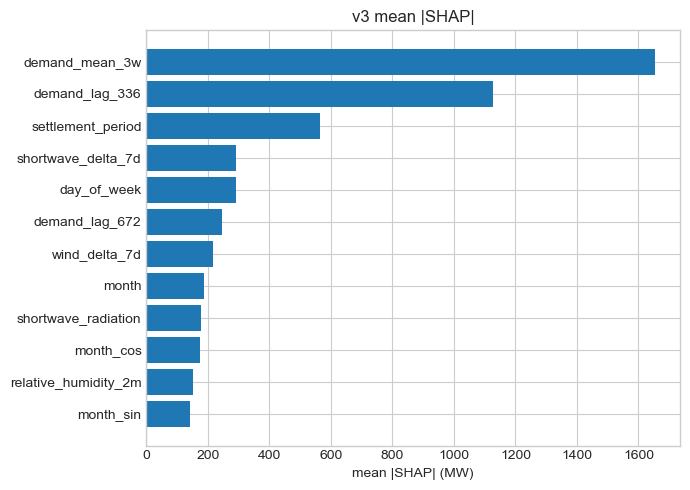

In [7]:
n = 2_500
need_v3 = [c for c in v3.features if c in holdout_v3.columns]
v3_s = holdout_v3.dropna(subset=["demand_mw", *need_v3]).sample(n, random_state=0)
if "region_id" not in v3_s.columns:
    v3_s["region_id"] = SERIES_ID
v3_shap = explain_scored(predict_quantiles(v3_s, v3), v3)["mean"]
v3_share = shap_source_share(v3_shap).assign(model="v3 engineered")
parts = [v3_share]
if v2 is not None:
    need_v2 = [c for c in v2.features if c in holdout_v2.columns]
    v2_s = holdout_v2.dropna(subset=["demand_mw", *need_v2]).sample(n, random_state=0)
    if "region_id" not in v2_s.columns:
        v2_s["region_id"] = SERIES_ID
    v2_shap = explain_scored(predict_quantiles(v2_s, v2), v2)["mean"]
    parts.append(shap_source_share(v2_shap).assign(model="v2 long lag"))
share = pd.concat(parts, ignore_index=True)
print("Holdout |SHAP| share")
display(share.pivot(index="source", columns="model", values="share"))
print("v3 top features")
display(mean_abs_shap(v3_shap, n=15))
print("v3 engineered only")
eng = mean_abs_shap(v3_shap, n=40)
display(eng.loc[eng["feature"].isin(WEEK_ENGINEERED_FEATURES)])

fig, ax = plt.subplots(figsize=(7, 5))
rank = mean_abs_shap(v3_shap, n=12)
ax.barh(rank["feature"].iloc[::-1], rank["mean_abs_shap"].iloc[::-1])
ax.set_title("v3 mean |SHAP|")
ax.set_xlabel("mean |SHAP| (MW)")
fig.tight_layout()

## 7. Promote (optional)

Copies v3 over `data/models`. Hour and day folders are untouched. Live week `run_pack` will see `long_lags_only` and skip recursive `lag_48`.

Copies v3 over `data/models`. Hour and day folders are untouched. Live week `run_pack` will see `long_lags_only` and skip recursive `lag_48`.

In [8]:
PROMOTE = False
if PROMOTE:
    from energy_forecast.paths import DATA_MODELS
    import shutil

    DATA_MODELS.mkdir(parents=True, exist_ok=True)
    for src in OUT_DIR.glob("*"):
        if src.is_file():
            shutil.copy2(src, DATA_MODELS / src.name)
    print("promoted week artefacts to", DATA_MODELS)
else:
    print("skipped promote; artefacts remain in", OUT_DIR)

skipped promote; artefacts remain in D:\energy-forecast\notebooks/week/v3\models
